# HTI Dataset Visualization

Produces summary plots for all six datasets. Outputs PNGs to `./hti_out/figures/`.

**Datasets covered:**
1. `compound_features_ecfp4.csv` - 2,319 compounds x 2,048-bit ECFP4
2. `target_features_aac.csv` - 1,341 proteins x 20-dim AAC
3. `compound_target_labeled.csv` - 14,166 positive C-T pairs
4. `compound_target_unlabeled.csv` - 3,095,613 unlabeled C-T pairs
5. `herb_compound_target.csv` - 126,830 H-C-T paths
6. `herb_compound_edges.tsv` - 5,005 H-C edges

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

# where the data lives
DATA_DIR = r"C:\Users\Nimishavarma\OneDrive\Dokumenty"
FIG_DIR  = os.path.join(os.getcwd(), "hti_out", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "figure.autolayout": True,
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})
sns.set_style("whitegrid")

print("Figures will be saved to:", FIG_DIR)

Figures will be saved to: c:\Users\Nimishavarma\OneDrive\Dokumenty\hti-project\hti_out\figures


In [2]:
# load everything (unlabeled file is 3M rows, keep only id columns to save memory)
ecfp = pd.read_csv(os.path.join(DATA_DIR, "compound_features_ecfp4.csv"))
aac  = pd.read_csv(os.path.join(DATA_DIR, "target_features_aac.csv"))
lab  = pd.read_csv(os.path.join(DATA_DIR, "compound_target_labeled.csv"))
unl  = pd.read_csv(os.path.join(DATA_DIR, "compound_target_unlabeled.csv"),
                   usecols=["compound_id", "protein_id"])
hct  = pd.read_csv(os.path.join(DATA_DIR, "herb_compound_target.csv"))
hce  = pd.read_csv(os.path.join(DATA_DIR, "herb_compound_edges.tsv"), sep="\t")

print(f"ecfp : {ecfp.shape}")
print(f"aac  : {aac.shape}")
print(f"lab  : {lab.shape}")
print(f"unl  : {unl.shape}")
print(f"hct  : {hct.shape}")
print(f"hce  : {hce.shape}")

ecfp : (2319, 2049)
aac  : (1341, 23)
lab  : (14166, 15)
unl  : (3095613, 2)
hct  : (126830, 22)
hce  : (8396, 14)


## Plot 1 - Dataset scale (one chart, all counts)

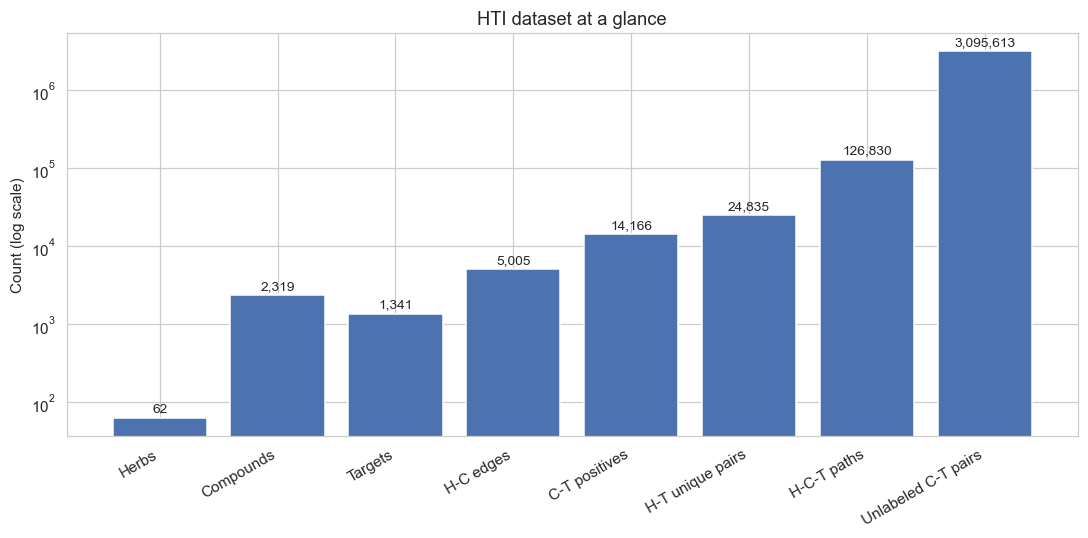

In [3]:
counts = {
    "Herbs":                   hce["herb_id"].nunique(),
    "Compounds":               ecfp["compound_id"].nunique(),
    "Targets":                 aac["protein_id"].nunique(),
    "H-C edges":               hce.drop_duplicates(["herb_id","compound_id"]).shape[0],
    "C-T positives":           lab.shape[0],
    "H-T unique pairs":        hct.drop_duplicates(["herb_id","protein_id"]).shape[0],
    "H-C-T paths":             hct.shape[0],
    "Unlabeled C-T pairs":     unl.shape[0]
}

fig, ax = plt.subplots(figsize=(10, 5))
names, values = list(counts.keys()), list(counts.values())
bars = ax.bar(names, values, color="#4C72B0")
ax.set_yscale("log")
ax.set_ylabel("Count (log scale)")
ax.set_title("HTI dataset at a glance")
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width()/2, v * 1.1, f"{v:,}",
            ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=30, ha="right")
plt.savefig(os.path.join(FIG_DIR, "01_counts.png"), bbox_inches="tight")
plt.show()

## Plot 2 - PU label imbalance (positives vs unlabeled)

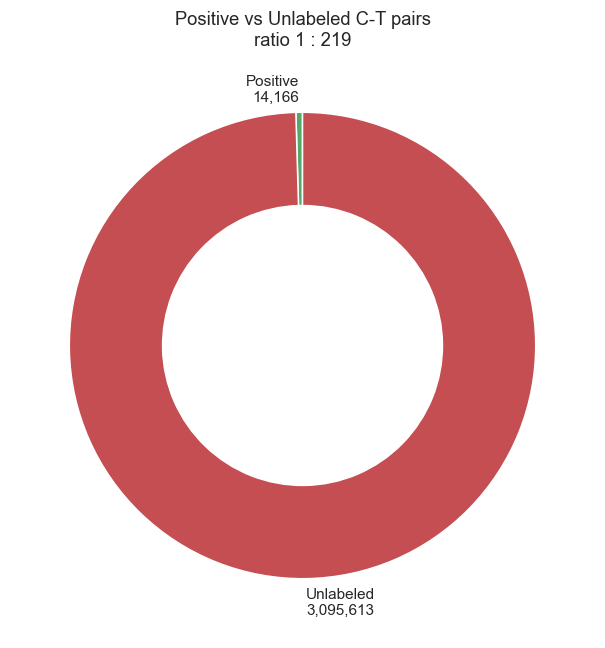

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
sizes = [lab.shape[0], unl.shape[0]]
labels = [f"Positive\n{lab.shape[0]:,}", f"Unlabeled\n{unl.shape[0]:,}"]
wedges, _ = ax.pie(sizes, labels=labels, colors=["#55A868", "#C44E52"],
                   wedgeprops=dict(width=0.4), startangle=90)
ratio = unl.shape[0] / lab.shape[0]
ax.set_title(f"Positive vs Unlabeled C-T pairs\nratio 1 : {ratio:.0f}")
plt.savefig(os.path.join(FIG_DIR, "02_pu_imbalance.png"), bbox_inches="tight")
plt.show()

## Plot 3 - Degree distributions (four small panels)

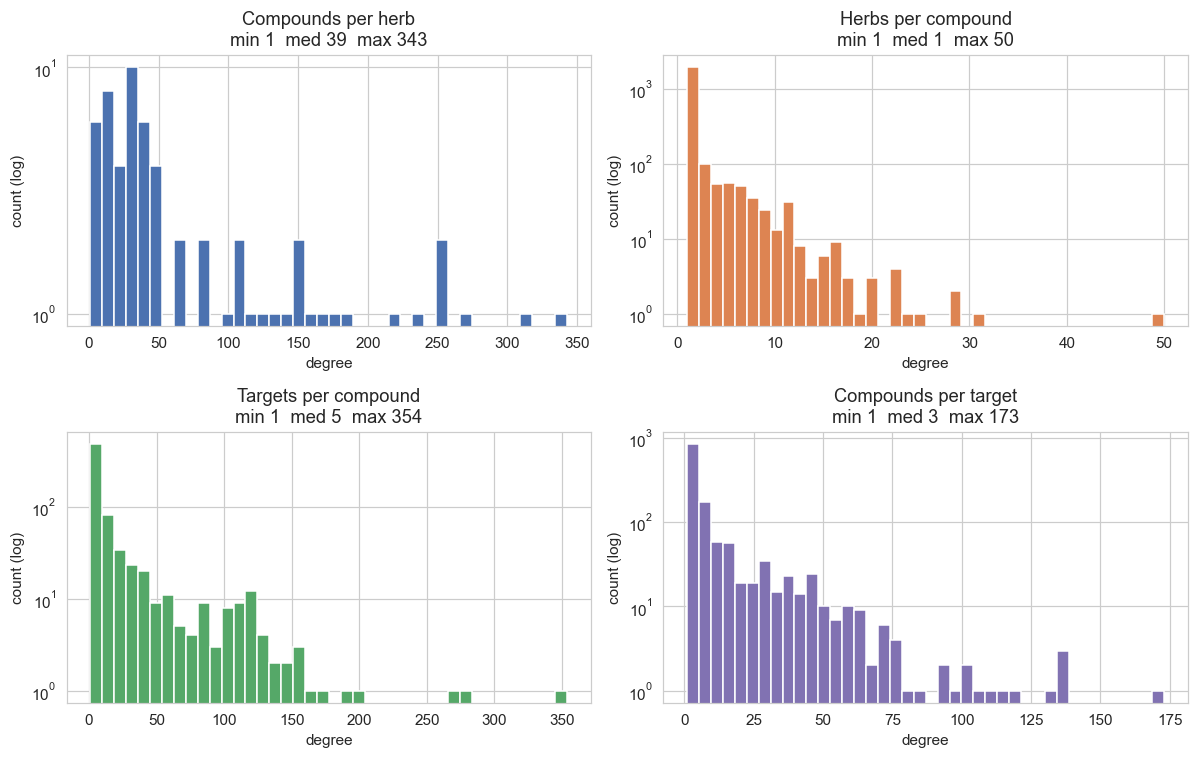

In [5]:
hc_edges = hce.drop_duplicates(["herb_id", "compound_id"])

deg_cmp_per_herb = hc_edges.groupby("herb_id").size()
deg_herb_per_cmp = hc_edges.groupby("compound_id").size()
deg_tgt_per_cmp  = lab.groupby("compound_id").size()
deg_cmp_per_tgt  = lab.groupby("protein_id").size()

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [
    (axes[0, 0], deg_cmp_per_herb, "Compounds per herb",   "#4C72B0"),
    (axes[0, 1], deg_herb_per_cmp, "Herbs per compound",   "#DD8452"),
    (axes[1, 0], deg_tgt_per_cmp,  "Targets per compound", "#55A868"),
    (axes[1, 1], deg_cmp_per_tgt,  "Compounds per target", "#8172B2")
]
for ax, s, title, col in panels:
    ax.hist(s.values, bins=40, color=col, edgecolor="white")
    ax.set_yscale("log")
    ax.set_title(f"{title}\nmin {s.min()}  med {int(s.median())}  max {s.max()}")
    ax.set_xlabel("degree")
    ax.set_ylabel("count (log)")
plt.savefig(os.path.join(FIG_DIR, "03_degree_distributions.png"), bbox_inches="tight")
plt.show()

## Plot 4 - Top 15 herbs by unique targets

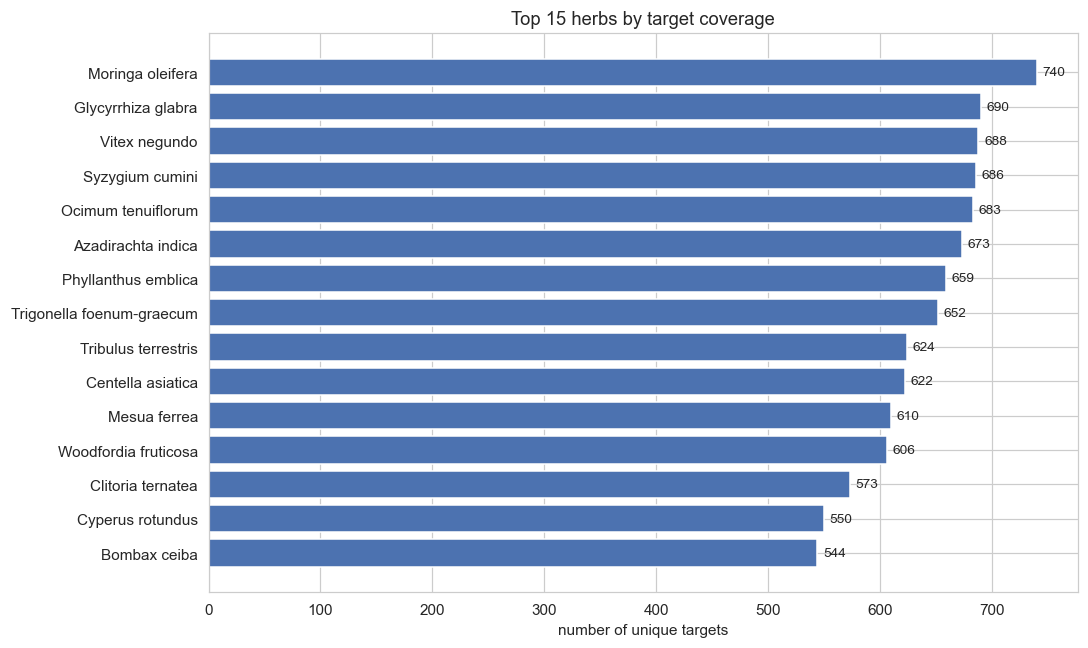

In [6]:
top_herbs = (hct.groupby("herb_botanical_name")["protein_id"]
                .nunique()
                .sort_values(ascending=True)
                .tail(15))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_herbs.index, top_herbs.values, color="#4C72B0")
ax.set_xlabel("number of unique targets")
ax.set_title("Top 15 herbs by target coverage")
for i, v in enumerate(top_herbs.values):
    ax.text(v + 5, i, str(v), va="center", fontsize=9)
plt.savefig(os.path.join(FIG_DIR, "04_top_herbs.png"), bbox_inches="tight")
plt.show()

## Plot 5 - Top 15 targets by linking herbs

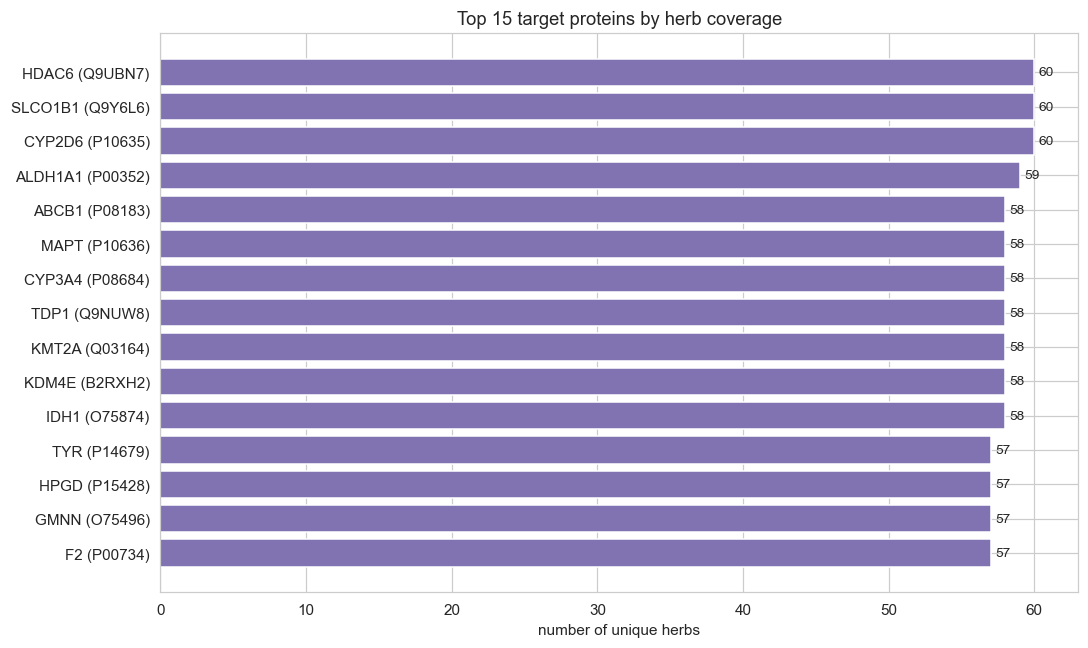

In [7]:
top_tgts = (hct.groupby(["protein_id", "hgnc_symbol"])
               ["herb_id"].nunique()
               .sort_values(ascending=True)
               .tail(15))
labels = [f"{sym} ({pid.split(':')[-1]})" for pid, sym in top_tgts.index]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(labels, top_tgts.values, color="#8172B2")
ax.set_xlabel("number of unique herbs")
ax.set_title("Top 15 target proteins by herb coverage")
for i, v in enumerate(top_tgts.values):
    ax.text(v + 0.3, i, str(v), va="center", fontsize=9)
plt.savefig(os.path.join(FIG_DIR, "05_top_targets.png"), bbox_inches="tight")
plt.show()

## Plot 6 - Plant part distribution

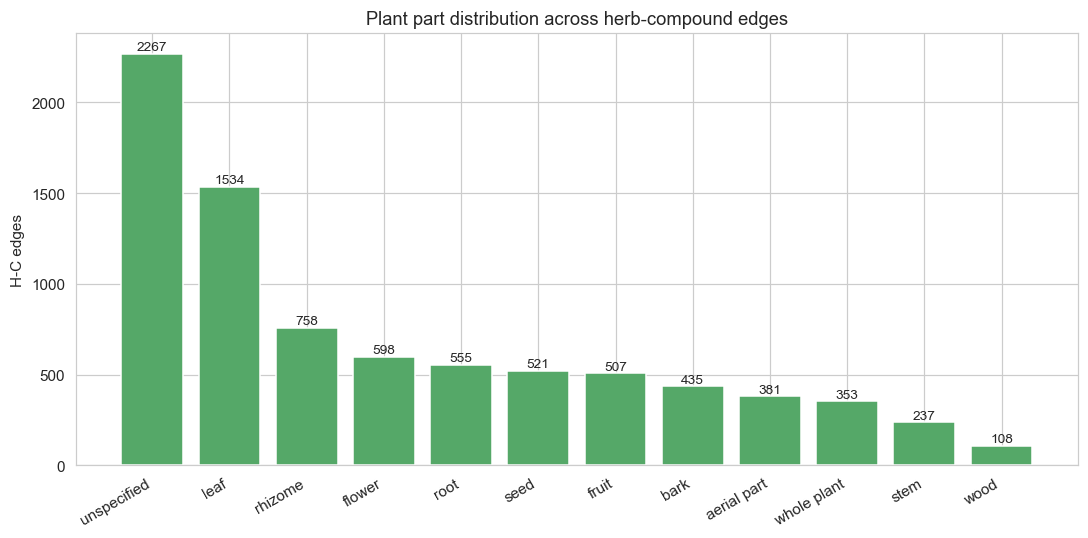

In [8]:
pp = hce["plant_part"].fillna("unspecified").value_counts().head(12)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pp.index, pp.values, color="#55A868")
ax.set_ylabel("H-C edges")
ax.set_title("Plant part distribution across herb-compound edges")
plt.xticks(rotation=30, ha="right")
for i, v in enumerate(pp.values):
    ax.text(i, v + 20, str(v), ha="center", fontsize=9)
plt.savefig(os.path.join(FIG_DIR, "06_plant_parts.png"), bbox_inches="tight")
plt.show()

## Plot 7 - ECFP4 bit density per compound

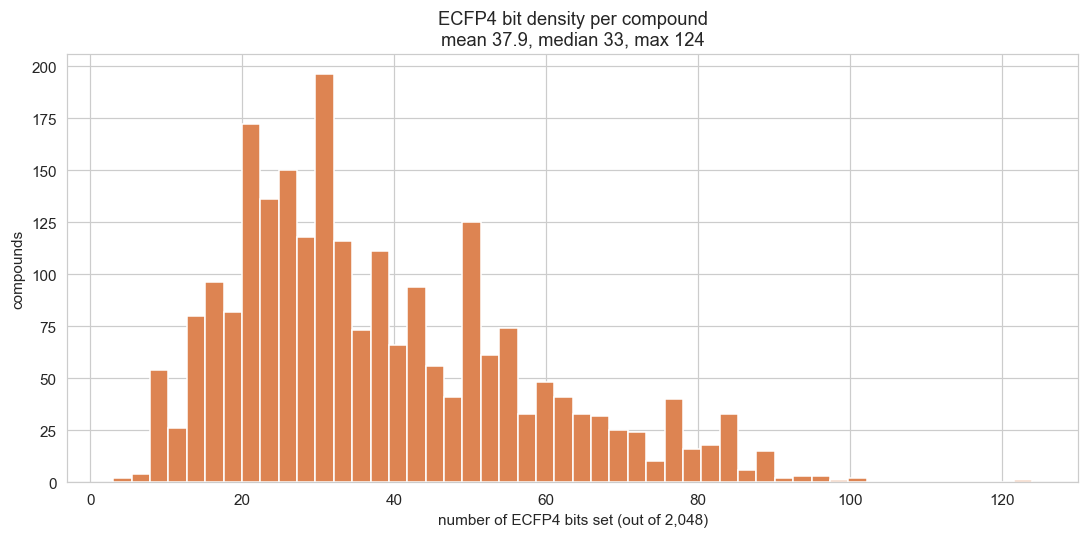

In [9]:
bit_cols = [c for c in ecfp.columns if c.startswith("ecfp4_")]
bits_set = ecfp[bit_cols].sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(bits_set, bins=50, color="#DD8452", edgecolor="white")
ax.set_xlabel("number of ECFP4 bits set (out of 2,048)")
ax.set_ylabel("compounds")
ax.set_title(f"ECFP4 bit density per compound\n"
             f"mean {bits_set.mean():.1f}, median {int(bits_set.median())}, "
             f"max {int(bits_set.max())}")
plt.savefig(os.path.join(FIG_DIR, "07_ecfp4_density.png"), bbox_inches="tight")
plt.show()

## Plot 8 - Amino acid composition distribution across targets

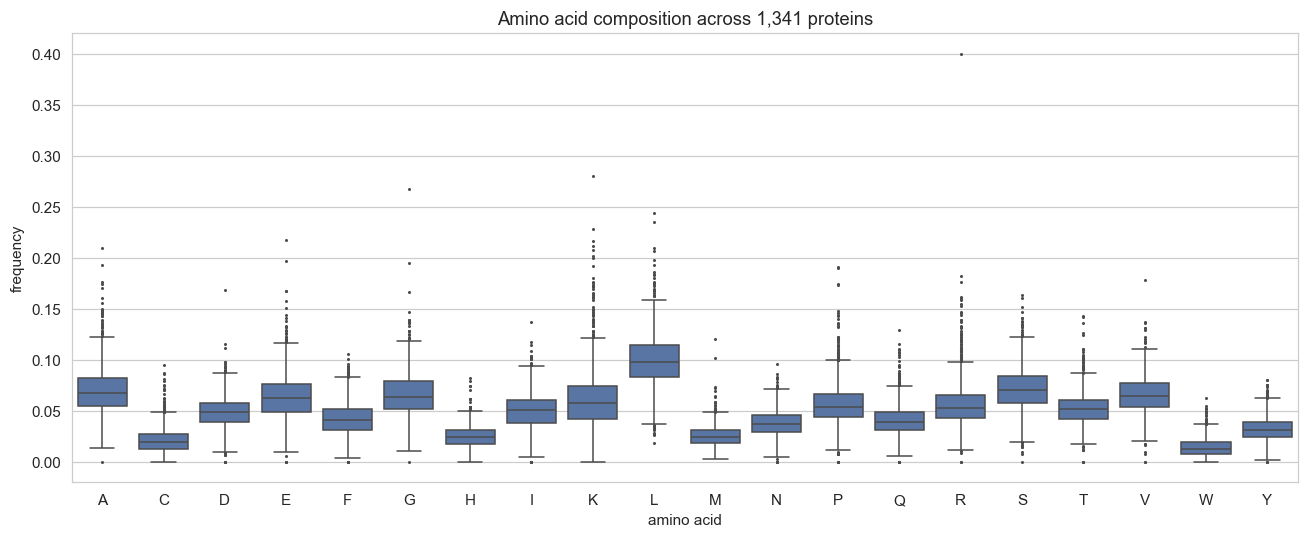

In [10]:
aac_cols = [c for c in aac.columns if c.startswith("aac_")]
aac_long = aac[aac_cols].melt(var_name="amino_acid", value_name="frequency")
aac_long["amino_acid"] = aac_long["amino_acid"].str.replace("aac_", "")

fig, ax = plt.subplots(figsize=(12, 5))
order = sorted(aac_long["amino_acid"].unique())
sns.boxplot(x="amino_acid", y="frequency", data=aac_long,
            order=order, color="#4C72B0", fliersize=1, ax=ax)
ax.set_xlabel("amino acid")
ax.set_ylabel("frequency")
ax.set_title("Amino acid composition across 1,341 proteins")
plt.savefig(os.path.join(FIG_DIR, "08_aac_boxplot.png"), bbox_inches="tight")
plt.show()

## Plot 9 - Sampled H -> C -> T subgraph

Takes 5 top herbs, their compounds, and each compound's top-3 targets. Draws a readable network.

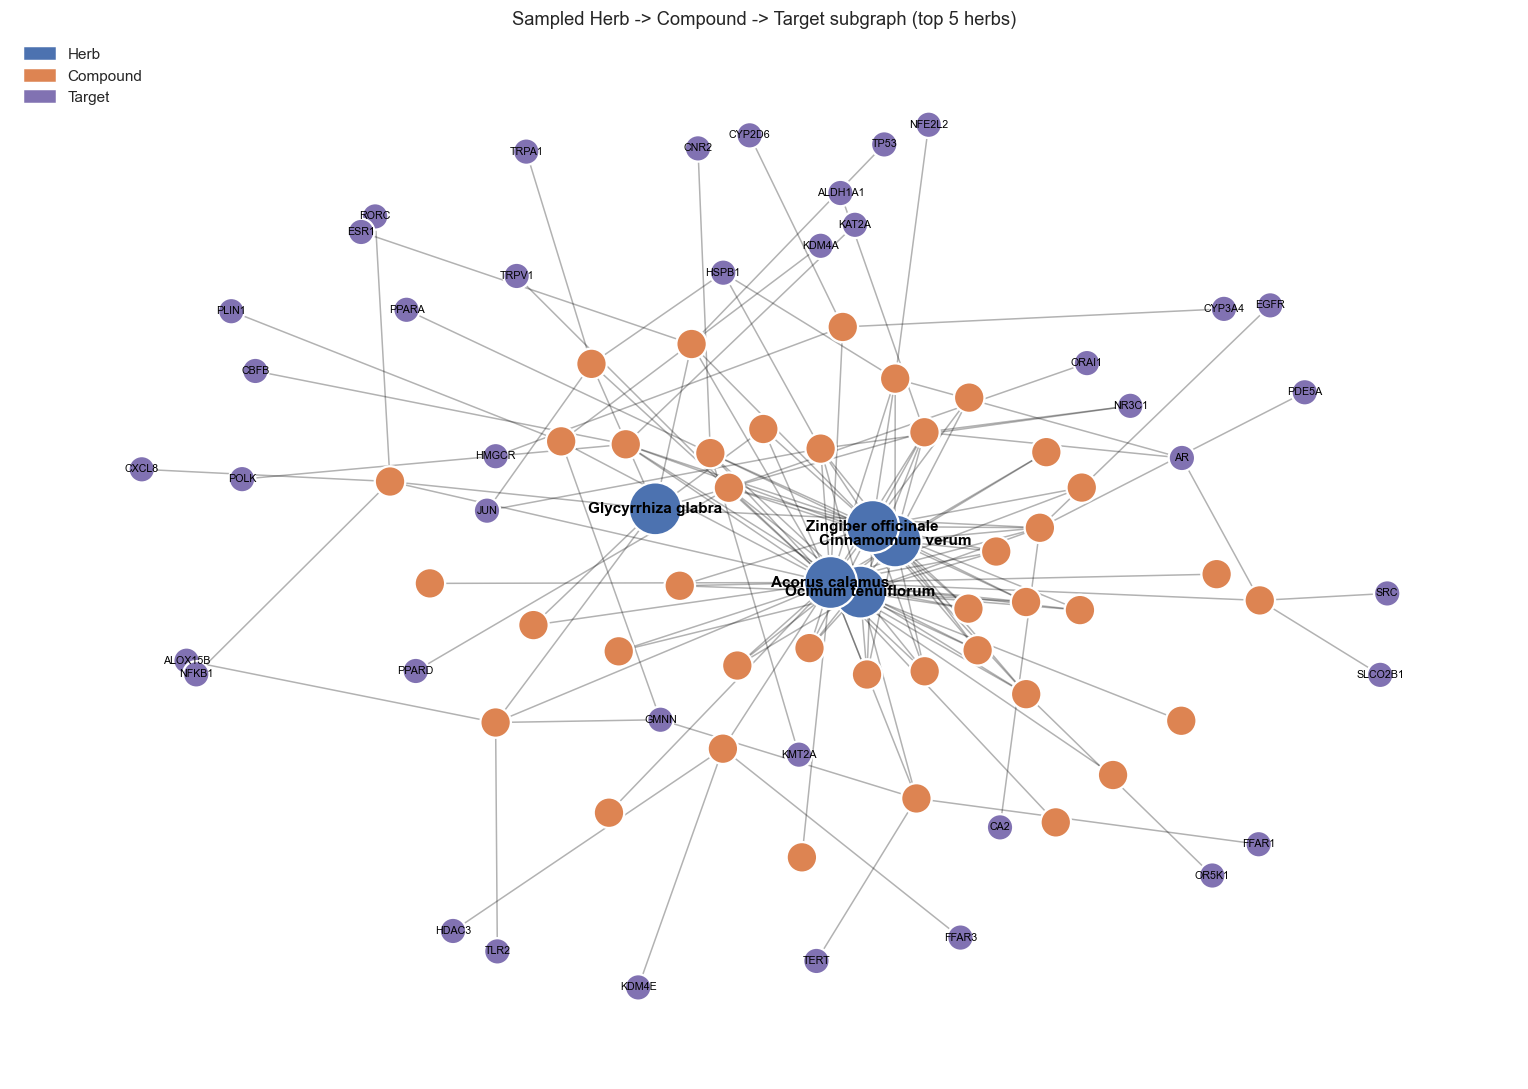

In [11]:
# pick top 5 herbs by compound count
top5_herbs = (hc_edges.groupby("herb_id").size().sort_values(ascending=False).head(5).index.tolist())
herb_names = (hce.drop_duplicates("herb_id").set_index("herb_id")["botanical_name"].to_dict())

sub_hc = hc_edges[hc_edges["herb_id"].isin(top5_herbs)]
sub_cids = sub_hc["compound_id"].unique()

# for each compound keep up to 3 targets
sub_ct = (lab[lab["compound_id"].isin(sub_cids)]
              .groupby("compound_id").head(3))

G = nx.Graph()
for hid in top5_herbs:
    G.add_node(hid, kind="H", label=herb_names[hid])
for cid in sub_hc["compound_id"].unique():
    G.add_node(cid, kind="C", label=cid.replace("IMPPAT3_PHYID", ""))
for _, r in sub_hc.iterrows():
    G.add_edge(r["herb_id"], r["compound_id"])
for _, r in sub_ct.iterrows():
    tgt = r["protein_id"]
    sym = r["hgnc_symbol"]
    G.add_node(tgt, kind="T", label=sym)
    G.add_edge(r["compound_id"], tgt)

# limit to a legible size
if G.number_of_nodes() > 120:
    keep_c = list(sub_hc["compound_id"].unique())[:40]
    G = G.subgraph(top5_herbs + keep_c +
                   [t for t in G.nodes if G.nodes[t].get("kind") == "T"
                    and any(c in keep_c for c in G.neighbors(t))]).copy()

pos = nx.spring_layout(G, k=0.6, seed=42, iterations=60)
colors = {"H": "#4C72B0", "C": "#DD8452", "T": "#8172B2"}
sizes  = {"H": 1200, "C": 400, "T": 300}
node_colors = [colors[G.nodes[n]["kind"]] for n in G.nodes]
node_sizes  = [sizes[G.nodes[n]["kind"]] for n in G.nodes]

fig, ax = plt.subplots(figsize=(14, 10))
nx.draw_networkx_edges(G, pos, alpha=0.3, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes,
                       edgecolors="white", linewidths=1.5, ax=ax)
herb_labels = {n: G.nodes[n]["label"] for n in G.nodes if G.nodes[n]["kind"] == "H"}
tgt_labels  = {n: G.nodes[n]["label"] for n in G.nodes if G.nodes[n]["kind"] == "T"}
nx.draw_networkx_labels(G, pos, herb_labels, font_size=10, font_weight="bold", ax=ax)
nx.draw_networkx_labels(G, pos, tgt_labels, font_size=7, ax=ax)
ax.set_axis_off()
ax.set_title("Sampled Herb -> Compound -> Target subgraph (top 5 herbs)")
# legend
import matplotlib.patches as mpatches
handles = [mpatches.Patch(color=colors[k], label=lbl)
           for k, lbl in zip("HCT", ["Herb", "Compound", "Target"])]
ax.legend(handles=handles, loc="upper left", frameon=False)
plt.savefig(os.path.join(FIG_DIR, "09_subgraph.png"), bbox_inches="tight")
plt.show()

## Plot 10 - Herb x top-50 target heatmap

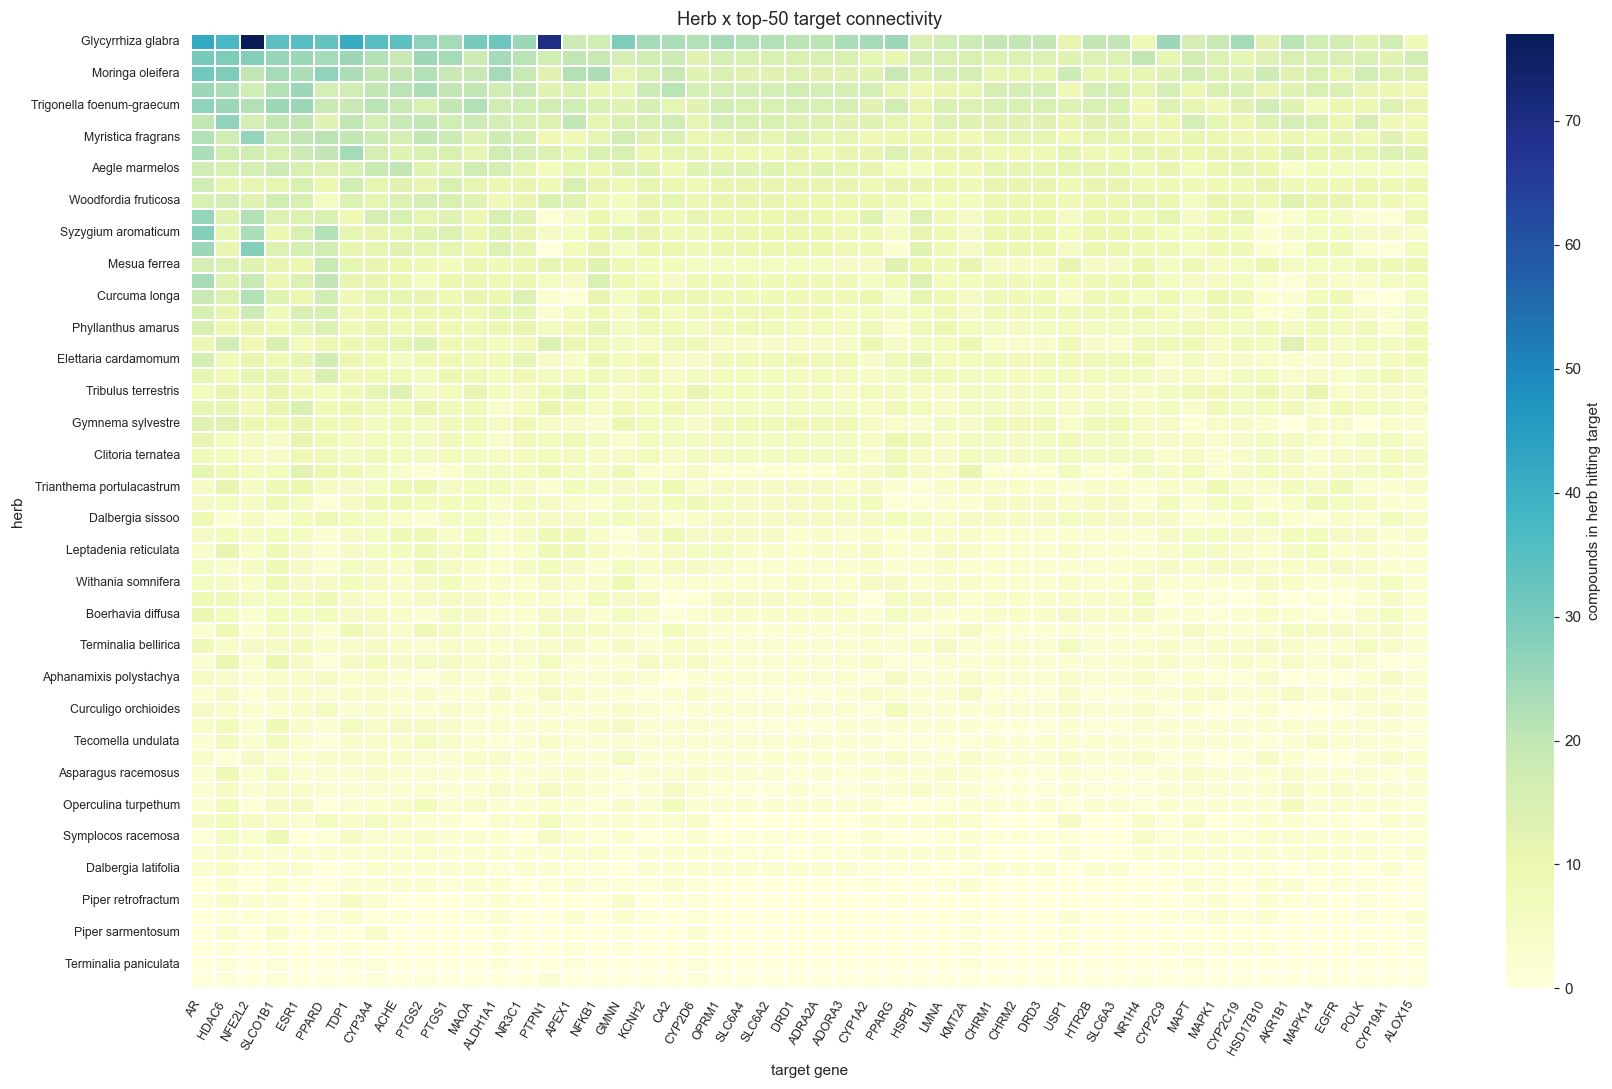

In [12]:
# how many compounds in each herb hit each target
mat = (hct.drop_duplicates(["herb_id", "compound_id", "protein_id"])
            .groupby(["herb_botanical_name", "hgnc_symbol"])
            .size()
            .unstack(fill_value=0))

# pick the 50 most common targets and sort herbs by total coverage
top50 = mat.sum(axis=0).sort_values(ascending=False).head(50).index
mat50 = mat[top50]
herb_order = mat50.sum(axis=1).sort_values(ascending=False).index
mat50 = mat50.loc[herb_order]

fig, ax = plt.subplots(figsize=(16, 10))
sns.heatmap(mat50, cmap="YlGnBu", linewidths=0.3, linecolor="white",
            cbar_kws={"label": "compounds in herb hitting target"},
            ax=ax)
ax.set_xlabel("target gene")
ax.set_ylabel("herb")
ax.set_title("Herb x top-50 target connectivity")
plt.xticks(rotation=60, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.savefig(os.path.join(FIG_DIR, "10_herb_target_heatmap.png"), bbox_inches="tight")
plt.show()

## Summary

In [13]:
print("All figures saved to:", FIG_DIR)
for f in sorted(os.listdir(FIG_DIR)):
    size_kb = os.path.getsize(os.path.join(FIG_DIR, f)) / 1024
    print(f"  {f}  ({size_kb:.0f} KB)")

All figures saved to: c:\Users\Nimishavarma\OneDrive\Dokumenty\hti-project\hti_out\figures
  01_counts.png  (71 KB)
  02_pu_imbalance.png  (48 KB)
  03_degree_distributions.png  (72 KB)
  04_top_herbs.png  (92 KB)
  05_top_targets.png  (95 KB)
  06_plant_parts.png  (69 KB)
  07_ecfp4_density.png  (44 KB)
  08_aac_boxplot.png  (52 KB)
  09_subgraph.png  (450 KB)
  10_herb_target_heatmap.png  (218 KB)
